# Grouping Cities to Compare Living Conditions
Ziyao Zeng | Adapted from STAT 437 Assignment 7

## 1. Research motivation and dataset
People considering a move may care about the overall living environment, which depends on more than wealth alone. I use five well-being indicators to group cities and compare their living conditions. The goal is to help people identify types of cities that may suit their priorities.

This notebook develops the analysis used in the report. It keeps every code excerpt from the report and adds the data checks, score plots, and calculations behind the findings.

The cleaned dataset was supplied with STAT 437 Assignment 7. It contains 155 cities and five numerical indicators: Purchase Power, Health Care, Pollution, Quality of Life, and Crime Rating. City, Country, and Region identify the cities and are kept out of the distance calculations.

The course materials identify the source as MoveHub, with the full dataset available at [MoveHub City Rankings on Kaggle](https://www.kaggle.com/datasets/blitzr/movehub-city-rankings). I use the supplied CSV directly; it is included next to this notebook.

Run the cells in order from this folder. The required packages are pandas, numpy, matplotlib, seaborn, and scikit-learn. If needed, install them with `python -m pip install pandas numpy matplotlib seaborn scikit-learn`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE

## 2. Check the data and scale the indicators
I first look at the original data, its data types, and any missing values. The supplied file is already cleaned, so I check it before using it rather than adding another cleaning step.

In [2]:
df_raw = pd.read_csv("movehub_data_cleaned2.csv")  # inspect the supplied data
print(df_raw.shape)
print(df_raw.head().to_string(index=False))
print(df_raw.dtypes)
print(df_raw.isna().sum())

(155, 8)
         City            Country      Region  Purchase Power  Health Care  Pollution  Quality of Life  Crime Rating
Santo Domingo Dominican Republic   Caribbean           28.82        62.50      18.59            41.88         62.19
         Baku         Azerbaijan    Caucasus           11.38        28.70      49.47            17.20         36.69
      Nairobi              Kenya East Africa           15.82        61.34      39.16            14.36         71.88
    Hong Kong          Hong Kong   East Asia           50.07        67.59      14.88            59.50         16.31
        Tokyo              Japan   East Asia           47.57        71.53      30.54            69.29         13.91
City                   str
Country                str
Region                 str
Purchase Power     float64
Health Care        float64
Pollution          float64
Quality of Life    float64
Crime Rating       float64
dtype: object
City               0
Country            0
Region             0
Pu

The five indicators have different variances and spreads, which could give some variables too much weight in the clustering. I look at their descriptive statistics and then use StandardScaler to put them on a similar scale.

In [3]:
num_cols = ["Purchase Power", "Health Care", "Pollution", "Quality of Life", "Crime Rating"]
print(df_raw[num_cols].describe().round(2).to_string())

       Purchase Power  Health Care  Pollution  Quality of Life  Crime Rating
count          155.00       155.00     155.00           155.00        155.00
mean            48.79        66.10      40.10            61.43         43.21
std             20.43        15.33      24.00            22.99         16.79
min             11.25        20.83       0.00             5.29         10.86
25%             32.60        59.29      21.22            42.74         29.76
50%             51.03        68.06      30.55            69.91         43.33
75%             62.53        77.56      59.73            79.98         53.77
max             91.85        91.90      89.10            93.05         85.70


In [4]:
df = pd.read_csv("movehub_data_cleaned2.csv")  # load city data
scaler = StandardScaler()
num_cols = ["Purchase Power", "Health Care", "Pollution", "Quality of Life", "Crime Rating"]
# scale numerical indicators
df[num_cols] = scaler.fit_transform(df[num_cols])

In [5]:
# Check the numerical variables after scaling.
print(df[num_cols].agg(['mean', 'std']).round(2).to_string())

      Purchase Power  Health Care  Pollution  Quality of Life  Crime Rating
mean            -0.0          0.0       -0.0              0.0           0.0
std              1.0          1.0        1.0              1.0           1.0


After scaling, the indicators have means close to zero and standard deviations close to one. I use these scaled values for distances and keep the city names for interpreting the results.

## 3. Compare clustering methods
I compare single, average, complete, and Ward linkage for k=2 through 11. These methods differ in how they measure the distance between groups. Higher silhouette scores suggest closer similarity within groups and better separation between groups.

The following loop is the code shown in the report. I add a score curve for each method so I can see how its results change with k, instead of looking only at the best score.

single best k = 2 score = 0.217


average best k = 2 score = 0.356


complete best k = 2 score = 0.381
ward best k = 2 score = 0.365


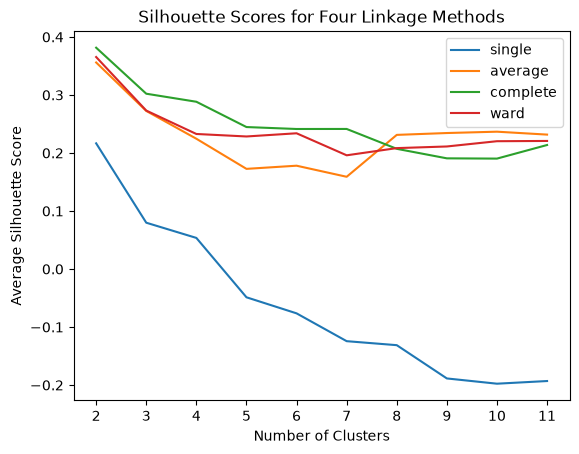

In [6]:
for link in ['single', 'average', 'complete', 'ward']:  # compare linkage methods
    avg_ss = []
    for k in range(2, 12):
        hac = AgglomerativeClustering(n_clusters=k, linkage=link)
        Y_pred = hac.fit_predict(df[num_cols])
        avg_ss.append(silhouette_score(df[num_cols], Y_pred))  # silhouette score
    print(link, "best k =", avg_ss.index(max(avg_ss)) + 2, "score =", round(max(avg_ss), 3))
    plt.plot(range(2, 12), avg_ss, label=link)  # compare the score curves

plt.xlabel('Number of Clusters')
plt.ylabel('Average Silhouette Score')
plt.xticks(range(2, 12))
plt.title('Silhouette Scores for Four Linkage Methods')
plt.legend()
plt.show()

Complete linkage with k=2 gives the highest silhouette score, about 0.38. I use it as a starting point, then compare k=2 and k=3 more closely to see whether a finer division would help describe living conditions.

In [7]:
for k in [2, 3]:
    hac = AgglomerativeClustering(n_clusters=k, linkage='complete')
    cluster_labels = hac.fit_predict(df[num_cols])
    print('k =', k, 'silhouette =', round(silhouette_score(df[num_cols], cluster_labels), 3))

k = 2 silhouette = 0.381
k = 3 silhouette = 0.302


### Compare k=2 and k=3 visually
I use t-SNE to show the cities in two dimensions and color the points by their cluster labels. The clustering itself still uses the five scaled indicators. The first plot below shows k=2 and the second shows k=3.

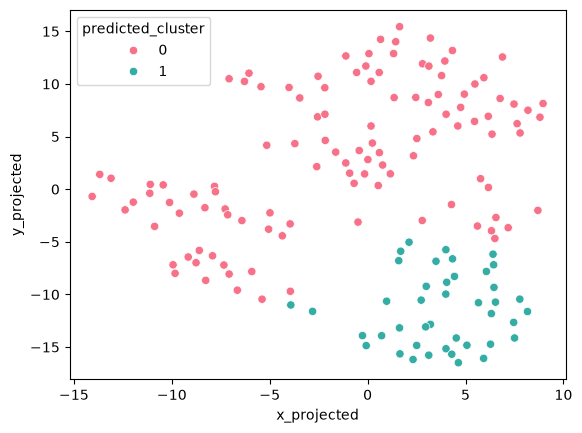

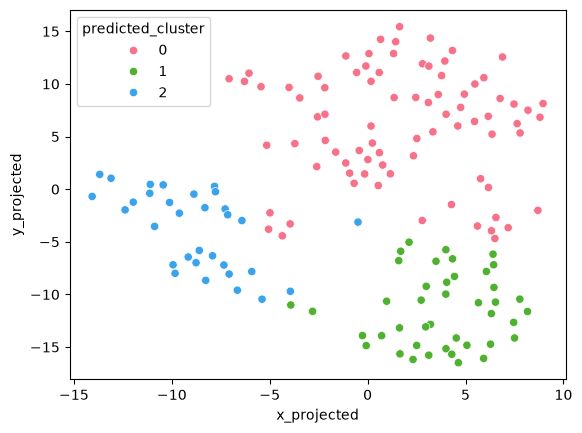

In [8]:
tsne = TSNE(n_components=2, perplexity=20, random_state=88)  # t-SNE model
data_tsne = tsne.fit_transform(df[num_cols])
df_tsne = pd.DataFrame(data_tsne, columns=["x_projected", "y_projected"], index=df.index)
df_combo = pd.concat([df, df_tsne], axis=1)  # combine city data and coordinates
for k in [2, 3]:
    hac = AgglomerativeClustering(n_clusters=k, linkage='complete')
    df_combo['predicted_cluster'] = hac.fit_predict(df[num_cols])  # cluster labels
    sns.scatterplot(x='x_projected', y='y_projected', hue='predicted_cluster',
                    palette=sns.color_palette("husl", k), data=df_combo)
    plt.show()  # compare clusterings

To see which group splits, I compare the two sets of labels directly. This helps connect the change in the plots to the actual city groups.

In [9]:
labels2 = AgglomerativeClustering(n_clusters=2, linkage='complete').fit_predict(df[num_cols])
labels3 = AgglomerativeClustering(n_clusters=3, linkage='complete').fit_predict(df[num_cols])
print(pd.crosstab(labels2, labels3, rownames=['k=2'], colnames=['k=3']))  # check the split

k=3   0   1   2
k=2            
0    81   0  32
1     0  42   0


The plots seem to show about three groups. With k=3, Cluster 0 from the k=2 result splits into Cluster 0 and Cluster 2, while Cluster 1 stays together. This separates the upper and lower-left groups more clearly. Although the silhouette score falls to about 0.30, I choose k=3 because it keeps this extra distinction rather than combining both areas into one cluster.

## 4. Compare the three groups
I now use complete linkage with k=3. The boxplot function below keeps the loop from my homework and lets me compare each indicator across the same three groups.

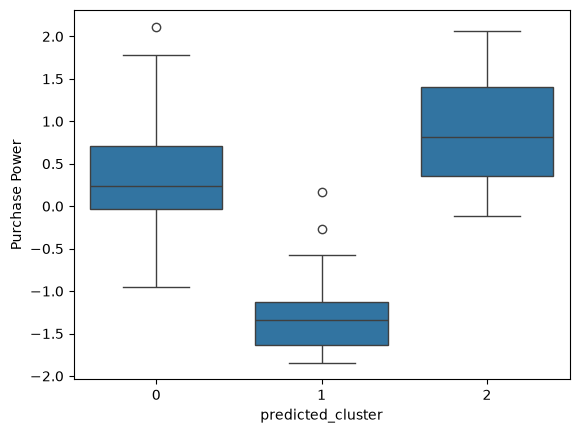

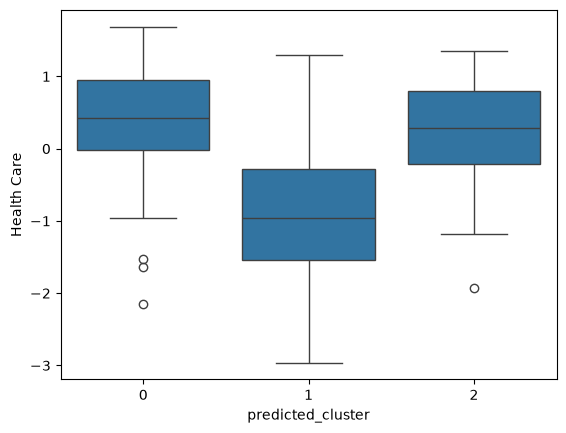

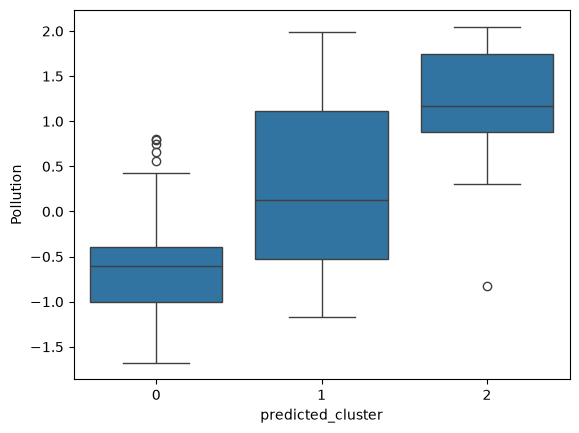

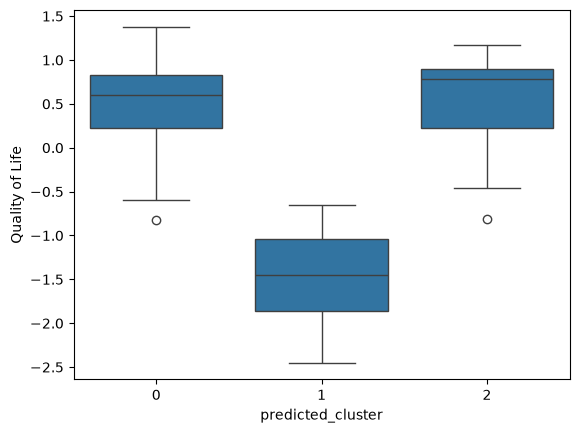

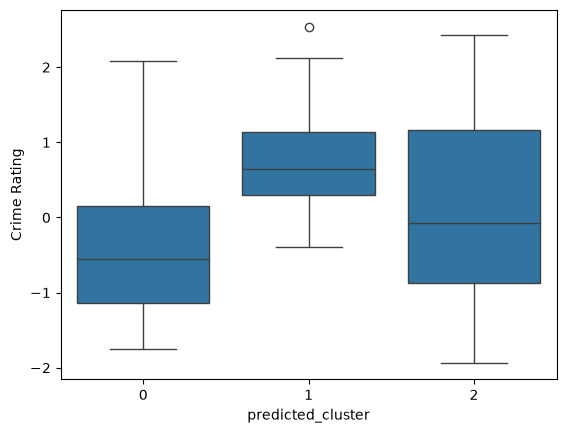

In [10]:
hac = AgglomerativeClustering(n_clusters=3, linkage='complete')  # final model
df['predicted_cluster'] = hac.fit_predict(df[num_cols])
# compare indicators across clusters
def compare_clusters(df, num_cols):
    for col in num_cols:
        sns.boxplot(x='predicted_cluster', y=col, data=df)
        plt.show()
compare_clusters(df, num_cols)  # draw boxplots

The boxplots show how each indicator varies within and between the groups. I also calculate the group means, using the same code as the report, to make the main differences easier to compare.

In [11]:
cluster_means = df.groupby('predicted_cluster')[num_cols].mean()  # group means
cluster_means = cluster_means.round(2)
print(cluster_means.to_string())

                   Purchase Power  Health Care  Pollution  Quality of Life  Crime Rating
predicted_cluster                                                                       
0                            0.32         0.39      -0.62             0.53         -0.47
1                           -1.29        -0.92       0.29            -1.43          0.79
2                            0.89         0.22       1.19             0.54          0.16


Cluster 0 tends to have better health care and quality of life, together with lower pollution and crime ratings. Cluster 1 generally has lower purchasing power, health care, and quality of life, along with higher crime ratings. Cluster 2 has the highest average purchasing power and pollution, while its average quality-of-life score is close to Cluster 0. This is why the extra group is useful: similar overall quality of life can come with different living conditions.

### Find a representative city for each group
To make these profiles more concrete, I find the city closest to the mean profile of each cluster. I calculate Euclidean distance across all five scaled indicators. I use the unrounded means for this calculation; the rounding above is only for displaying the table.

In [12]:
centers = df.groupby('predicted_cluster')[num_cols].mean()  # unrounded group centers
representative_cities = []

for cluster in sorted(df['predicted_cluster'].unique()):
    group = df[df['predicted_cluster'] == cluster].copy()
    distances = np.sqrt(((group[num_cols] - centers.loc[cluster]) ** 2).sum(axis=1))
    closest_city = group.loc[distances.idxmin()]  # nearest city in this group
    representative_cities.append({'Cluster': cluster, 'City': closest_city['City'], 'Country': closest_city['Country']})

representative_cities = pd.DataFrame(representative_cities)
print(representative_cities.to_string(index=False))

 Cluster    City       Country
       0  Sydney     Australia
       1    Lima          Peru
       2 Orlando United States


The closest cities are Sydney in Cluster 0, Lima in Cluster 1, and Orlando in Cluster 2. These examples help put a city name alongside each profile in the report.

## 5. Conclusion
The three groups show why wealth alone is not enough to compare places to live. Someone who values lower pollution and crime might start with Cluster 0, while someone who puts more weight on purchasing power might compare cities in Cluster 2. These profiles give people a clearer way to narrow down cities that match their preferences.